In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

In [6]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [7]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [8]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [9]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [10]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [11]:
def getRcErr(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    p = n_ss/(n_ss+n_os)
    return 2*np.sqrt(p*(1-p)/(n_ss+n_os))

In [12]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [13]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s']

In [ ]:
df_uncut = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0415_pt10_m0_new.root', "ResultTree"),'10<pts<30')

In [12]:
df_uncut.shape[0]

3488007

include neutral pairs

In [ ]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2', 'q0', 'q2']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s', 'q0s', 'q2s']
df = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0415_pt10_m0_new.root', "ResultTree"),'10<pts<30 and bs!=-9')

observables1 = ['pt','b','dr','z','epair','w','reject', 'pt1', 'pt2', 'q0', 'q2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects', 'pt1s', 'pt2s', 'q0s', 'q2s']
df_geant = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

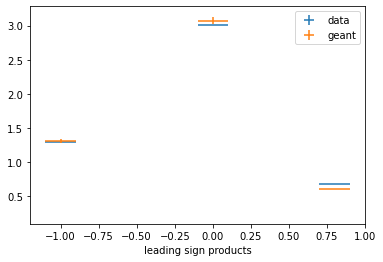

In [46]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>10, df.pts<15)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

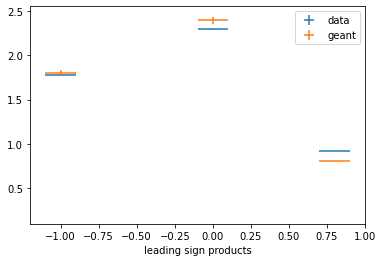

In [36]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>15, df.pts<20)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

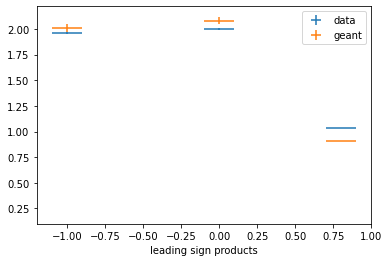

In [73]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>20, df.pts<30)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<30)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<30)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

In [74]:
print(y_data)
print(y_geant)

[1.96318628 0.         0.         0.         0.         2.00274767
 0.         0.         0.         1.03406605]
[2.01152113 0.         0.         0.         0.         2.0812254
 0.         0.         0.         0.90725347]


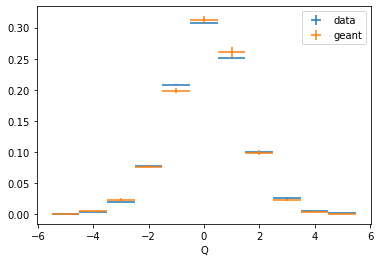

In [61]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>10, df.pts<15)]['q0s'], bins=np.arange(-5,7), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['q0s'], bins=np.arange(-5,7), weights=df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.5, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.5, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

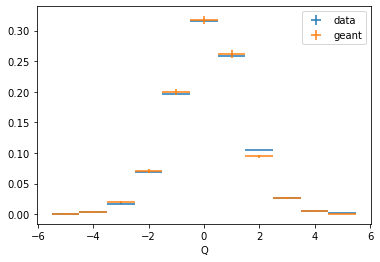

In [60]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>15, df.pts<20)]['q0s'], bins=np.arange(-5,7), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['q0s'], bins=np.arange(-5,7), weights=df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.5, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.5, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

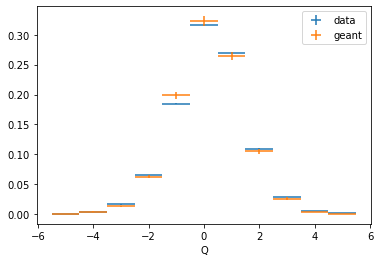

In [62]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>20, df.pts<25)]['q0s'], bins=np.arange(-5,7), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<25)]['q0s'], bins=np.arange(-5,7), weights=df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<25)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.5, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.5, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

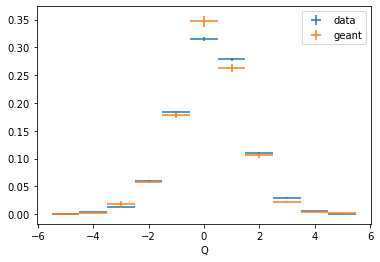

In [63]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>25, df.pts<30)]['q0s'], bins=np.arange(-5,7), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>25, df_geant.pts<30)]['q0s'], bins=np.arange(-5,7), weights=df_geant[np.logical_and(df_geant.pts>25, df_geant.pts<30)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.5, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.5, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

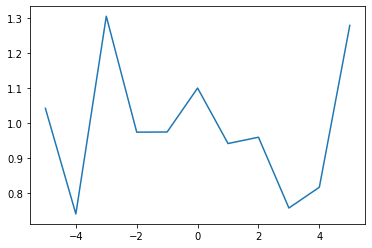

In [64]:
plt.plot(x[:-1], y_geant/y_data)

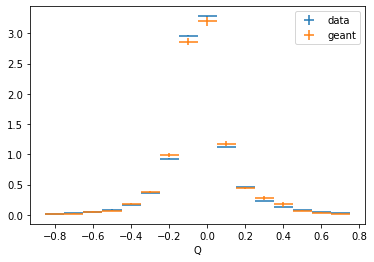

In [68]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>10, df.pts<15)]['q2s'], bins=np.arange(-0.8,0.9,0.1), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['q2s'], bins=np.arange(-0.8,0.9,0.1), weights=df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.05, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.05, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

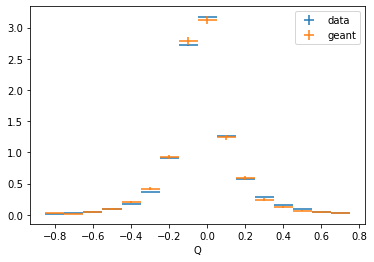

In [69]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>15, df.pts<20)]['q2s'], bins=np.arange(-0.8,0.9,0.1), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['q2s'], bins=np.arange(-0.8,0.9,0.1), weights=df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.05, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.05, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

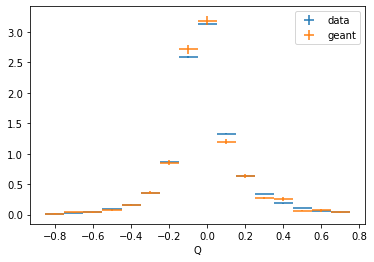

In [70]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>20, df.pts<25)]['q2s'], bins=np.arange(-0.8,0.9,0.1), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<25)]['q2s'], bins=np.arange(-0.8,0.9,0.1), weights=df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<25)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.05, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.05, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

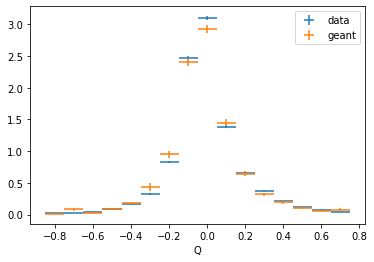

In [71]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>25, df.pts<30)]['q2s'], bins=np.arange(-0.8,0.9,0.1), density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>25, df_geant.pts<30)]['q2s'], bins=np.arange(-0.8,0.9,0.1), weights=df_geant[np.logical_and(df_geant.pts>25, df_geant.pts<30)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.05, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.05, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('Q')
#plt.ylim(bottom=0.1)
plt.legend()

don't include neutral pairs

In [14]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s']
df = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0415_pt10_m0_new.root', "ResultTree"),'bs!=0 and 10<pts<30 and bs!=-9')

Warning in <TClass::Init>: no dictionary for class TStarJetVectorJet is available
Warning in <TClass::Init>: no dictionary for class TStarJetVector is available


In [15]:
observables1 = ['pt','b','dr','z','epair','w','reject', 'pt1', 'pt2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects', 'pt1s', 'pt2s']
df_geant = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

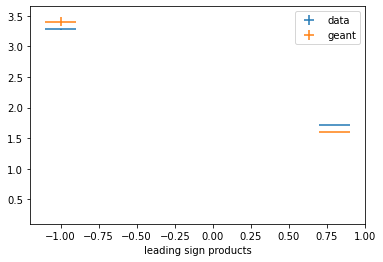

In [77]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>10, df.pts<15)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>10, df_geant.pts<15)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

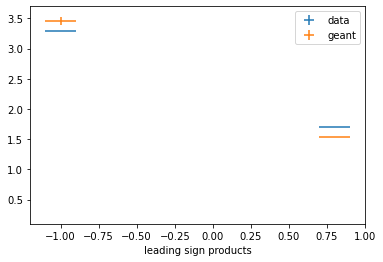

In [78]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>15, df.pts<20)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>15, df_geant.pts<20)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

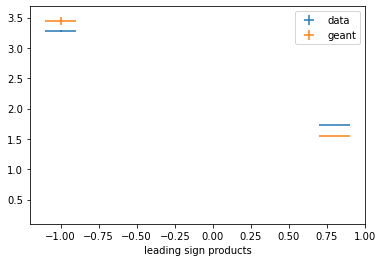

In [79]:
y_data, yerr_data, x = calc_hist(df[np.logical_and(df.pts>20, df.pts<30)]['bs'], density=True)
y_geant, yerr_geant, x = calc_hist(df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<30)]['bs'], weights=df_geant[np.logical_and(df_geant.pts>20, df_geant.pts<30)]['w'], density=True)
plt.errorbar(x[:-1], y_data, xerr=0.1, yerr=yerr_data, label='data', ls='none')
plt.errorbar(x[:-1], y_geant, xerr=0.1, yerr=yerr_geant, label='geant', ls='none')
plt.xlabel('leading sign products')
plt.ylim(bottom=0.1)
plt.legend()

In [80]:
print(y_data)
print(y_geant)

[3.27497666 0.         0.         0.         0.         0.
 0.         0.         0.         1.72502334]
[3.44583156 0.         0.         0.         0.         0.
 0.         0.         0.         1.55416844]


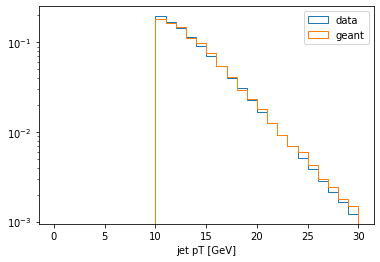

In [13]:
plt.hist(df['pts'], range=(0,30), bins=30, histtype='step', label='data', density=True)
plt.hist(df_geant['pts'], range=(0,30), bins=30, histtype='step', weights=df_geant['w'], label='geant', density=True)
plt.xlabel('jet pT [GeV]')
plt.yscale('log')
plt.legend()

In [ ]:
plt.hist(df['pt1s'], range=(0,30), bins=30, histtype='step', label='leading data', density=True)
plt.hist(df['pt2s'], range=(0,30), bins=30, histtype='step', label='subleading data', density=True)
plt.hist(df_geant['pt1s'], range=(0,30), bins=30, histtype='step', weights=df_geant['w'], label='leading geant', density=True)
plt.hist(df_geant['pt2s'], range=(0,30), bins=30, histtype='step', weights=df_geant['w'], label='subleading geant', density=True)
plt.xlabel('track pT [GeV]')
plt.yscale('log')
plt.legend()

In [ ]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s']
df = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0415_pt10_m0_new.root', "ResultTree"),'bs!=0 and 10<pts<30 and bs!=-9')

In [ ]:
observables1 = ['pt','b','dr','z','epair','w','reject', 'pt1', 'pt2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects', 'pt1s', 'pt2s']
df_geant = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

In [16]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [17]:
rcs_0 = getRc(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcErr(applyCut(df,'10<pts<15'))

In [18]:
rcs_1 = getRc(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcErr(applyCut(df,'15<pts<20'))

In [19]:
rcs_2 = getRc(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcErr(applyCut(df,'20<pts<30'))

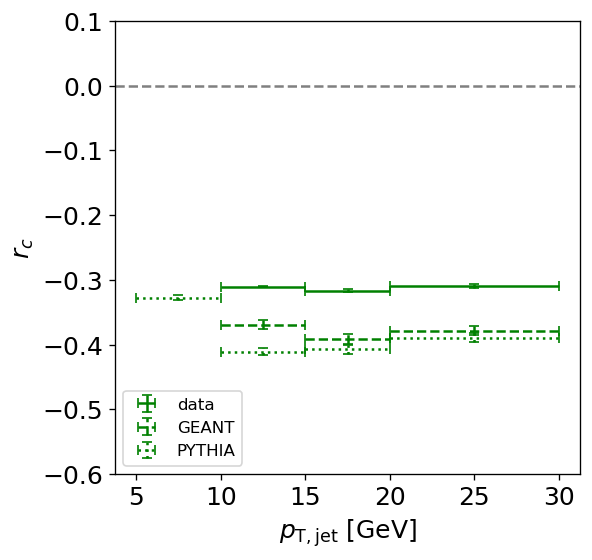

In [20]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='data')
eb1=plt.errorbar([12.5, 17.5, 25], [-0.3692052788091335,-0.39125448790132333,-0.37896559276422115], xerr=[2.5, 2.5, 5], yerr=[0.006897886850187349,0.007238693512313462,0.006992252096104474], capsize=3, color='g', ls='none', label='GEANT')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
eb2=plt.errorbar([7.5, 12.5, 17.5, 25], [-0.327642,-0.411037,-0.406995,-0.389326], xerr=[2.5, 2.5, 2.5, 5], yerr=[0.00356854, 0.00528726, 0.0068786, 0.0065369], capsize=3, color='g', ls='none', label='PYTHIA')
eb2[-1][0].set_linestyle('dotted')
eb2[-1][1].set_linestyle('dotted')
plt.xlabel('$p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [21]:
print([rcs_0, rcs_1, rcs_2])

[-0.3108704349900626, -0.31656597136790693, -0.3099906629318394]


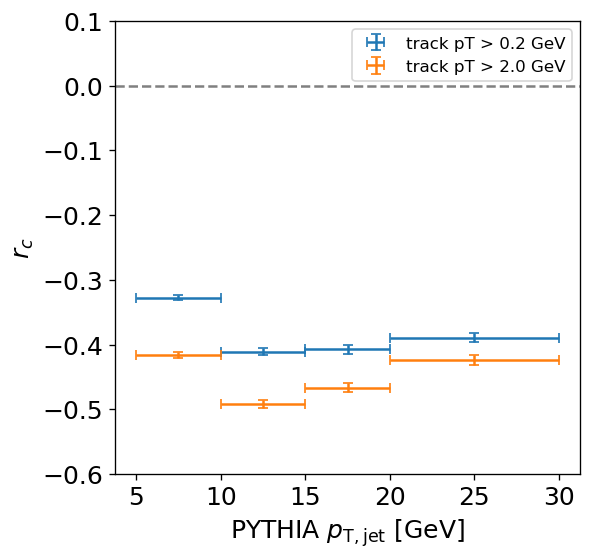

In [18]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([7.5, 12.5, 17.5, 25], [-0.327642,-0.411037,-0.406995,-0.389326], xerr=[2.5, 2.5, 2.5, 5], yerr=[0.00356854, 0.00528726, 0.0068786, 0.0065369], capsize=3, ls='none', label='track pT > 0.2 GeV')
plt.errorbar([7.5, 12.5, 17.5, 25], [-0.416899,-0.492089,-0.466525,-0.424216], xerr=[2.5, 2.5, 2.5, 5], yerr=[0.00460621, 0.00604822, 0.00755576, 0.00772293], capsize=3, ls='none', label='track pT > 2.0 GeV')
plt.xlabel('PYTHIA $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [24]:
df.eval('ts = 2*zs*(1-zs)*epairs/( ((1-zs)*epairs*sin(drs))**2 )', inplace=True)
#df.eval('ts = 2*(1-zs)/(zs*epairs*drs**2)', inplace=True)
#df.eval('ts = 1/(2*epairs*zs*(1-zs)*(1-cos(drs)))', inplace=True)

In [25]:
bins = 10.0**(np.arange(0,3.3,0.3))

In [26]:
bincenter = (bins[:-1] + bins[1:])/2

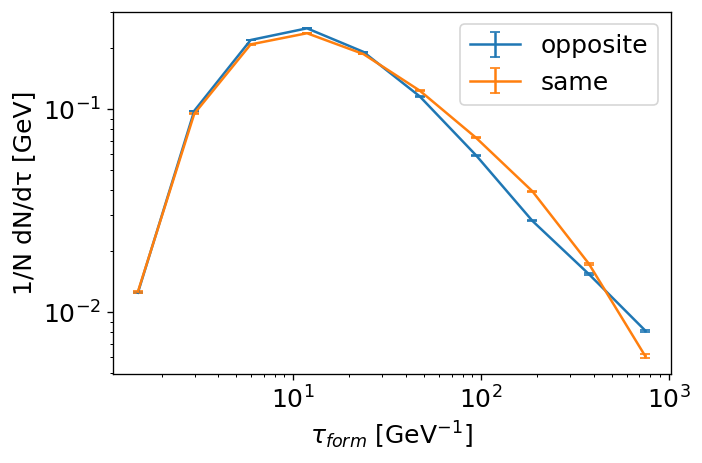

In [28]:
y_os, yerr_os = calc_hist(df[df.bs<0]['ts'], bins=bins, density=True)[:-1]
y_ss, yerr_ss = calc_hist(df[df.bs>0]['ts'], bins=bins, density=True)[:-1]
plt.errorbar(bincenter, y_os/sum(y_os), yerr=yerr_os, label='opposite', capsize=3)
plt.errorbar(bincenter, y_ss/sum(y_ss), yerr=yerr_ss, label='same', capsize=3)
plt.xlabel(r'$\tau_{form}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.xscale('log')
#plt.xlim(0.1, 1e4)
plt.legend()
plt.ylabel('1/N dN/dτ [GeV]', fontsize=15)
plt.yscale('log')

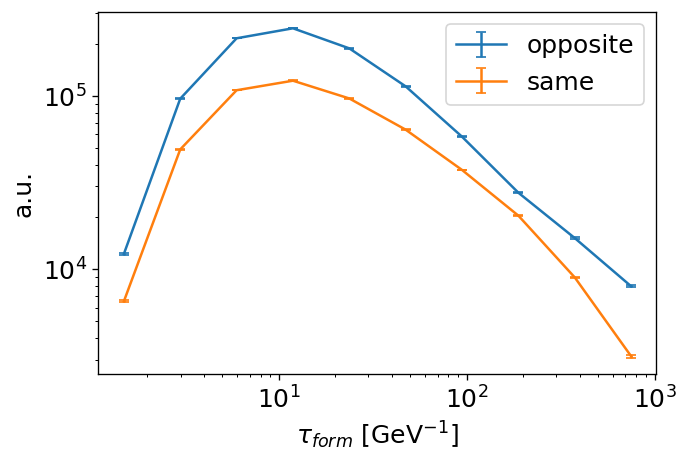

In [29]:
y_os, yerr_os = calc_hist(df[df.bs<0]['ts'], bins=bins)[:-1]
y_ss, yerr_ss = calc_hist(df[df.bs>0]['ts'], bins=bins)[:-1]
plt.errorbar(bincenter, y_os, yerr=yerr_os, label='opposite', capsize=3)
plt.errorbar(bincenter, y_ss, yerr=yerr_ss, label='same', capsize=3)
plt.xlabel(r'$\tau_{form}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.xscale('log')
#plt.xlim(0.1, 1e4)
plt.legend()
plt.ylabel('a.u.', fontsize=15)
plt.yscale('log')

In [30]:
dfs = []
for i in range(0, len(bincenter)):
    dfs.append(df[np.logical_and(df.ts>bins[i], df.ts<bins[i+1])])

In [63]:
rcs = []
rcs_err = []
for i in range(0, len(dfs)):
    rcs.append(getRc(applyCut(dfs[i],'10<pts<30')))
    rcs_err.append(getRcErr(applyCut(dfs[i],'10<pts<30')))

In [64]:
rcs_0 = []
rcs_err_0 = []
for i in range(0, len(dfs)):
    rcs_0.append(getRc(applyCut(dfs[i],'10<pts<15')))
    rcs_err_0.append(getRcErr(applyCut(dfs[i],'10<pts<15')))

In [65]:
rcs_1 = []
rcs_err_1 = []
for i in range(0, len(dfs)):
    rcs_1.append(getRc(applyCut(dfs[i],'15<pts<20')))
    rcs_err_1.append(getRcErr(applyCut(dfs[i],'15<pts<20')))

In [66]:
rcs_2 = []
rcs_err_2 = []
for i in range(0, len(dfs)):
    rcs_2.append(getRc(applyCut(dfs[i],'20<pts<30')))
    rcs_err_2.append(getRcErr(applyCut(dfs[i],'20<pts<30')))

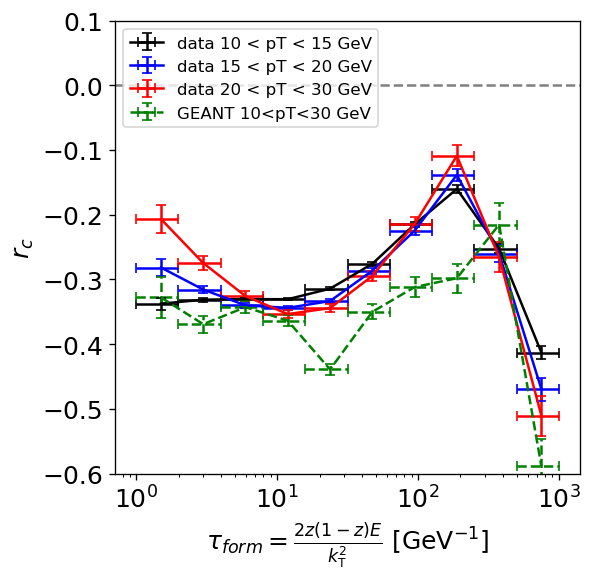

In [67]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs_0, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rcs_err_0, capsize=3, color='k', label='data 10 < pT < 15 GeV')
plt.errorbar(bincenter, rcs_1, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rcs_err_1, capsize=3, color='b', label='data 15 < pT < 20 GeV')
plt.errorbar(bincenter, rcs_2, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rcs_err_2, capsize=3, color='r', label='data 20 < pT < 30 GeV')
eb1=plt.errorbar(bincenter, [-0.327818, -0.369146, -0.342837, -0.363768, -0.439054, -0.350137, -0.311827, -0.298075, -0.21529, -0.588844],\
             xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=[0.0321407, 0.0133602, 0.00941942, 0.00846424, 0.00889042, 0.0114719, 0.0156647, 0.0222832, 0.0336142, 0.0423637],\
             capsize=3, color='g', label='GEANT 10<pT<30 GeV', ls='--')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
#plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')

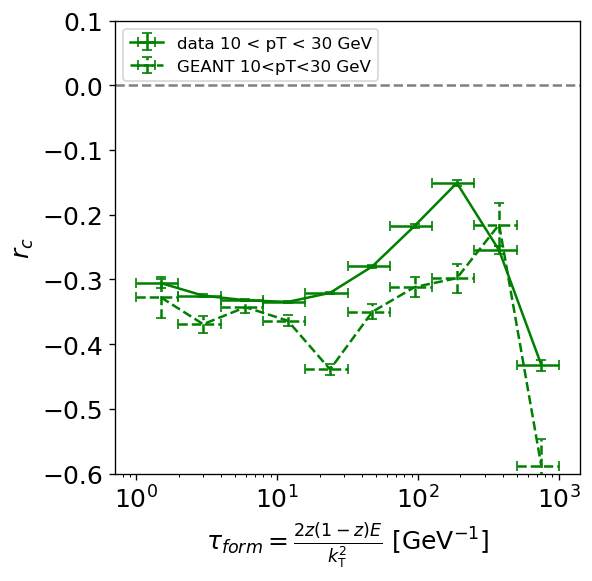

In [70]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rcs, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rcs_err, capsize=3, color='g', label='data 10 < pT < 30 GeV')
eb1=plt.errorbar(bincenter, [-0.327818, -0.369146, -0.342837, -0.363768, -0.439054, -0.350137, -0.311827, -0.298075, -0.21529, -0.588844],\
             xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=[0.0321407, 0.0133602, 0.00941942, 0.00846424, 0.00889042, 0.0114719, 0.0156647, 0.0222832, 0.0336142, 0.0423637],\
                          capsize=3, color='g', label='GEANT 10<pT<30 GeV', ls='--')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
#plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')